# 01. Data Understanding & Exploratory Data Analysis (Bab 4.1 - 4.4)

**Proyek:** Perbandingan Kinerja Naive Baseline, XGBoost, dan Long Short-Term Memory (LSTM) dalam Prediksi Jumlah Kasus Demam Berdarah Dengue (DBD) Berdasarkan Faktor Meteorologi di DKI Jakarta (2010-2024)  
**Tahap L-M-O-P:** `[L]` Learning Problem & Data Understanding (Minggu 2 / LKM 11 Poin 1-3)

**Tujuan Notebook:**
1. Memuat sumber data mentah dan membangun dataset integrasi bulanan DKI Jakarta (Januari 2010 - Juli 2024).
2. Mendokumentasikan informasi dataset dan deskripsi seluruh fitur (Bab 4.1 - 4.2).
3. Menganalisis kondisi data: missing values, duplikat, outlier, distribusi target, noise, serta asumsi time series (Bab 4.3).
4. Melakukan Exploratory Data Analysis (EDA) dengan 4 visualisasi beserta insight empiris (Bab 4.4).

## 1. Setup Environment & Memuat Dataset

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Deteksi root folder project secara otomatis (lokal maupun Colab)
cwd = Path.cwd().resolve()
if (cwd / "src").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "src").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Folder 'src' tidak ditemukan. Jalankan notebook dari root 'project/' atau 'project/notebooks/'.")

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from build_dataset import ensure_raw_datasets, build_monthly_dataset

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

print("Project root terdeteksi:", PROJECT_ROOT.name)
raw_paths = ensure_raw_datasets(allow_download=True)
df_climate = pd.read_csv(raw_paths["climate"])
df_dengue_weather_21_24 = pd.read_csv(raw_paths["dengue_weather_2021_2024"])
df_opendengue = pd.read_csv(raw_paths["opendengue"])

merged_path = PROJECT_ROOT / "data" / "merged" / "dki_jakarta_dengue_weather_2010_2024_monthly.csv"
df_merged = build_monthly_dataset(allow_download=True)

print(f"Dataset gabungan dimuat: {df_merged.shape[0]} baris x {df_merged.shape[1]} kolom")

Project root terdeteksi: project


Dataset gabungan dimuat: 175 baris x 15 kolom


**Catatan Pipeline Data:** Skrip `src/build_dataset.py` menggabungkan catatan meteorologi harian BMKG DKI Jakarta (Stasiun Kemayoran `96745` dan Tanjung Priok `96741`) periode 2010-2020 (`climate_data.csv`) dan 2021-2024 (`jakarta-dengue-weather_2021-2024.csv`) setelah membersihkan kode sentinel `>= 8888` dan nilai negatif, lalu mengagregasinya ke tingkat bulanan dan menggabungkannya dengan surveilans kasus DBD bulanan OpenDengue DKI Jakarta (`2010-01` s.d. `2024-07`).

## 4.1 Informasi Dataset

In [2]:
info_rows = [
    {
        "Dataset": "Indonesia Climate Daily (BMKG 2010-2020)",
        "Sumber / URL": "https://www.kaggle.com/datasets/greegtitan/indonesia-climate",
        "Jumlah Baris": df_climate.shape[0],
        "Jumlah Kolom": df_climate.shape[1],
        "Tipe": "Time Series Harian (Nasional)",
        "Ukuran File (MB)": round(raw_paths["climate"].stat().st_size / (1024**2), 3),
        "Format": "CSV",
    },
    {
        "Dataset": "Jakarta Dengue & Weather (BMKG 2021-2024)",
        "Sumber / URL": "https://www.kaggle.com/datasets/yutakatarokusumah/jakarta-dengue-weather-2021-2024",
        "Jumlah Baris": df_dengue_weather_21_24.shape[0],
        "Jumlah Kolom": df_dengue_weather_21_24.shape[1],
        "Tipe": "Time Series Harian (Jak-Pus & Jak-Ut)",
        "Ukuran File (MB)": round(raw_paths["dengue_weather_2021_2024"].stat().st_size / (1024**2), 3),
        "Format": "CSV",
    },
    {
        "Dataset": "OpenDengue DKI Jakarta (2004-2024)",
        "Sumber / URL": "https://opendengue.org/data.html (V1.3.1)",
        "Jumlah Baris": df_opendengue.shape[0],
        "Jumlah Kolom": df_opendengue.shape[1],
        "Tipe": "Time Series Bulanan (Provinsi DKI)",
        "Ukuran File (MB)": round(raw_paths["opendengue"].stat().st_size / (1024**2), 3),
        "Format": "CSV",
    },
    {
        "Dataset": "FINAL INTEGRATED: DKI Jakarta Dengue & Weather (2010-2024)",
        "Sumber / URL": "Integrasi OpenDengue + BMKG 96745 & 96741 (build_dataset.py)",
        "Jumlah Baris": df_merged.shape[0],
        "Jumlah Kolom": df_merged.shape[1],
        "Tipe": "Multivariate Time Series Bulanan",
        "Ukuran File (MB)": round(merged_path.stat().st_size / (1024**2), 4),
        "Format": "CSV",
    },
]

df_dataset_info = pd.DataFrame(info_rows)
display(df_dataset_info)
print(f"Rentang waktu final: {df_merged['ym'].min()} s.d. {df_merged['ym'].max()} ({len(df_merged)} bulan)")
display(df_merged.head())

,Dataset,Sumber / URL,Jumlah Baris,Jumlah Kolom,Tipe,Ukuran File (MB),Format
0,Indonesia Climate Daily (BMKG 2010-2020),https://www.kaggle.com/datasets/greegtitan/ind...,589265,12,Time Series Harian (Nasional),34.1840,CSV
1,Jakarta Dengue & Weather (BMKG 2021-2024),https://www.kaggle.com/datasets/yutakatarokusu...,2922,14,Time Series Harian (Jak-Pus & Jak-Ut),0.1960,CSV
2,OpenDengue DKI Jakarta (2004-2024),https://opendengue.org/data.html (V1.3.1),232,9,Time Series Bulanan (Provinsi DKI),0.0170,CSV
3,FINAL INTEGRATED: DKI Jakarta Dengue & Weather...,Integrasi OpenDengue + BMKG 96745 & 96741 (bui...,175,15,Multivariate Time Series Bulanan,0.0189,CSV


Rentang waktu final: 2010-01 s.d. 2024-07 (175 bulan)


,ym,date,year,month,Tn,Tx,Tavg,RH_avg,RR_total,RR_mean,rain_days,ss,ff_x,ff_avg,dengue_total
0,2010-01,2010-01-01,2010,1,24.854839,31.058065,27.525806,80.790323,490.265000,15.815000,22.0,2.724194,7.5,2.919355,1486.0
1,2010-02,2010-02-01,2010,2,25.303571,31.755357,28.087500,80.642857,288.100000,10.289286,18.0,4.205357,11.5,2.392857,1815.0
2,2010-03,2010-03-01,2010,3,25.919355,32.419355,28.653226,78.032258,228.310037,7.364840,12.0,5.124432,7.0,2.419355,2570.0
3,2010-04,2010-04-01,2010,4,26.650000,33.580000,29.648333,73.400000,24.360345,0.812011,6.0,5.365476,7.5,2.783333,2431.0
4,2010-05,2010-05-01,2010,5,26.548387,33.445161,29.280645,76.387097,112.361667,3.624570,13.0,5.002419,6.0,2.467742,1640.0


**Analisis Bab 4.1:** Dataset mentah terdiri dari tiga sumber terpisah. Setelah difilter khusus wilayah DKI Jakarta dan diagregasi secara temporal ke skala bulanan dari **Januari 2010 hingga Juli 2024**, dataset final yang digunakan untuk penelitian berjumlah **175 baris bulanan x 15 kolom** (ukuran memori RAM sangat ringan < 0.05 MB) dalam format CSV.

## 4.2 Deskripsi Fitur

In [3]:
feature_meta = {
    "ym": ("String (Period)", "Identitas periode tahun-bulan format YYYY-MM"),
    "date": ("String / Date", "Tanggal awal bulan (YYYY-MM-01) untuk pengindeksan deret waktu"),
    "year": ("Integer", "Tahun observasi (2010-2024)"),
    "month": ("Integer", "Bulan kalender (1-12)"),
    "Tn": ("Float (°C)", "Rata-rata suhu udara minimum harian pada bulan tersebut"),
    "Tx": ("Float (°C)", "Rata-rata suhu udara maksimum harian pada bulan tersebut"),
    "Tavg": ("Float (°C)", "Rata-rata suhu udara harian pada bulan tersebut"),
    "RH_avg": ("Float (%)", "Rata-rata kelembapan udara relatif pada bulan tersebut"),
    "RR_total": ("Float (mm)", "Estimasi total akumulasi curah hujan bulanan (RR_mean x jumlah hari bulan)"),
    "RR_mean": ("Float (mm/hari)", "Rata-rata intensitas curah hujan harian pada bulan tersebut"),
    "rain_days": ("Float (hari)", "Rata-rata jumlah hari hujan (RR > 0) per stasiun dalam sebulan"),
    "ss": ("Float (jam/hari)", "Rata-rata durasi penyinaran matahari harian"),
    "ff_x": ("Float (m/s)", "Rata-rata kecepatan angin maksimum bulanan antar stasiun"),
    "ff_avg": ("Float (m/s)", "Rata-rata kecepatan angin harian pada bulan tersebut"),
    "dengue_total": ("Float (kasus) [TARGET]", "Jumlah total kasus DBD bulanan di Provinsi DKI Jakarta (OpenDengue)"),
}

rows_desc = []
for col in df_merged.columns:
    sem_type, desc = feature_meta[col]
    samples = df_merged[col].dropna().head(3).tolist()
    samples_fmt = [round(x, 2) if isinstance(x, float) else x for x in samples]
    rows_desc.append({
        "Nama Fitur": col,
        "Dtype Pandas": str(df_merged[col].dtype),
        "Tipe & Satuan": sem_type,
        "Deskripsi": desc,
        "Contoh Nilai": str(samples_fmt),
    })

df_feature_desc = pd.DataFrame(rows_desc)
display(df_feature_desc)
print("\nRingkasan statistik deskriptif fitur numerik:")
display(df_merged.drop(columns=["year", "month"]).describe().T.round(2))

,Nama Fitur,Dtype Pandas,Tipe & Satuan,Deskripsi,Contoh Nilai
0,ym,str,String (Period),Identitas periode tahun-bulan format YYYY-MM,"['2010-01', '2010-02', '2010-03']"
1,date,str,String / Date,Tanggal awal bulan (YYYY-MM-01) untuk penginde...,"['2010-01-01', '2010-02-01', '2010-03-01']"
2,year,int64,Integer,Tahun observasi (2010-2024),"[2010, 2010, 2010]"
3,month,int64,Integer,Bulan kalender (1-12),"[1, 2, 3]"
4,Tn,float64,Float (°C),Rata-rata suhu udara minimum harian pada bulan...,"[24.85, 25.3, 25.92]"
5,Tx,float64,Float (°C),Rata-rata suhu udara maksimum harian pada bula...,"[31.06, 31.76, 32.42]"
6,Tavg,float64,Float (°C),Rata-rata suhu udara harian pada bulan tersebut,"[27.53, 28.09, 28.65]"
7,RH_avg,float64,Float (%),Rata-rata kelembapan udara relatif pada bulan ...,"[80.79, 80.64, 78.03]"
8,RR_total,float64,Float (mm),Estimasi total akumulasi curah hujan bulanan (...,"[490.26, 288.1, 228.31]"
9,RR_mean,float64,Float (mm/hari),Rata-rata intensitas curah hujan harian pada b...,"[15.81, 10.29, 7.36]"



Ringkasan statistik deskriptif fitur numerik:


,count,mean,std,min,25%,50%,75%,max
Tn,175.0,25.89,0.56,24.35,25.56,25.92,26.22,27.82
Tx,175.0,32.28,0.87,29.54,31.84,32.45,32.85,34.48
Tavg,175.0,28.61,0.64,26.74,28.25,28.67,28.96,30.47
RH_avg,175.0,76.28,3.96,67.45,73.69,76.66,78.93,85.55
RR_total,175.0,209.22,186.70,0.00,85.52,186.69,272.00,1060.07
RR_mean,175.0,6.94,6.36,0.00,2.80,6.07,8.83,36.55
rain_days,175.0,11.16,6.65,0.00,6.00,12.00,16.00,26.00
ss,175.0,4.81,1.42,1.02,3.79,4.79,5.76,7.91
ff_x,175.0,8.47,2.62,5.50,7.00,8.00,9.25,25.50
ff_avg,175.0,1.96,0.51,1.10,1.57,1.85,2.35,3.97


**Analisis Bab 4.2:** Seluruh **15 kolom** pada dataset terintegrasi memiliki peran yang jelas: 4 kolom pengenal temporal (`ym`, `date`, `year`, `month`), 10 fitur meteorologi agregat bulanan (suhu `Tn`, `Tx`, `Tavg`; kelembapan `RH_avg`; hujan `RR_total`, `RR_mean`, `rain_days`; penyinaran `ss`; angin `ff_x`, `ff_avg`), dan 1 variabel target regresi (`dengue_total`).

## 4.3 Kondisi Data (Kualitas, Missing Values, Duplikat, Outlier, Noise & Asumsi)

In [4]:
# 1. Missing Values
missing_cnt = df_merged.isna().sum()
missing_pct = (missing_cnt / len(df_merged) * 100).round(2)
df_missing = pd.DataFrame({"Missing Count": missing_cnt, "Missing (%)": missing_pct})
print("1. MISSING VALUES PER KOLOM:")
display(df_missing[df_missing["Missing Count"] > 0])
if df_missing["Missing Count"].sum() > 0:
    print("Detail baris target kosong:")
    display(df_merged[df_merged["dengue_total"].isna()][["ym", "Tavg", "RH_avg", "RR_total", "rain_days", "dengue_total"]])

# 2. Duplikat & Kontinuitas Bulan
dup_rows = int(df_merged.duplicated().sum())
dup_ym = int(df_merged["ym"].duplicated().sum())
expected_months = pd.period_range("2010-01", "2024-07", freq="M").astype(str).tolist()
missing_calendar = sorted(set(expected_months) - set(df_merged["ym"].tolist()))
print(f"\n2. DUPLIKAT & KONTINUITAS KALENDER:")
print(f"- Baris duplikat: {dup_rows} | Duplikat periode ym: {dup_ym}")
print(f"- Celah bulan kalender yang hilang: {len(missing_calendar)} ({missing_calendar})")

# 3. Deteksi Outlier (IQR)
num_features = ["Tn", "Tx", "Tavg", "RH_avg", "RR_total", "RR_mean", "rain_days", "ss", "ff_x", "ff_avg", "dengue_total"]
outlier_rows = []
for col in num_features:
    s = df_merged[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lb, ub = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lb) | (s > ub)).sum())
    outlier_rows.append({
        "Fitur": col,
        "Q1": round(q1, 2),
        "Median": round(s.median(), 2),
        "Q3": round(q3, 2),
        "Batas Atas IQR": round(ub, 2),
        "Jumlah Outlier IQR": n_out,
        "Persentase (%)": round(n_out / len(df_merged) * 100, 2),
    })

print("\n3. PEMERIKSAAN OUTLIER (METODE IQR):")
display(pd.DataFrame(outlier_rows))

# 4. Skewness Target & Sentinel Check
print("\n4. DISTRIBUSI TARGET & PEMERIKSAAN NOISE/SENTINEL:")
print(f"- Skewness dengue_total: {df_merged['dengue_total'].skew():.3f}")
print(f"- Nilai ekstrem BMKG >= 8888 tersisa: {int((df_merged[num_features] >= 8888).sum().sum())}")
print(f"- Nilai negatif tersisa: {int((df_merged[num_features] < 0).sum().sum())}")

1. MISSING VALUES PER KOLOM:


,Missing Count,Missing (%)
dengue_total,3,1.71


Detail baris target kosong:


,ym,Tavg,RH_avg,RR_total,rain_days,dengue_total
15,2011-04,28.541667,75.433333,77.761905,12.5,NaN
73,2016-02,27.846552,82.775862,522.541396,19.5,NaN
128,2020-09,29.508824,70.058824,14.681818,1.5,NaN



2. DUPLIKAT & KONTINUITAS KALENDER:
- Baris duplikat: 0 | Duplikat periode ym: 0
- Celah bulan kalender yang hilang: 0 ([])

3. PEMERIKSAAN OUTLIER (METODE IQR):


,Fitur,Q1,Median,Q3,Batas Atas IQR,Jumlah Outlier IQR,Persentase (%)
0,Tn,25.56,25.92,26.22,27.22,5,2.86
1,Tx,31.84,32.45,32.85,34.37,8,4.57
2,Tavg,28.25,28.67,28.96,30.04,6,3.43
3,RH_avg,73.69,76.66,78.93,86.81,0,0.00
4,RR_total,85.52,186.69,272.00,551.73,10,5.71
5,RR_mean,2.80,6.07,8.83,17.88,12,6.86
6,rain_days,6.00,12.00,16.00,31.00,0,0.00
7,ss,3.79,4.79,5.76,8.72,0,0.00
8,ff_x,7.00,8.00,9.25,12.62,12,6.86
9,ff_avg,1.57,1.85,2.35,3.52,1,0.57



4. DISTRIBUSI TARGET & PEMERIKSAAN NOISE/SENTINEL:
- Skewness dengue_total: 1.964
- Nilai ekstrem BMKG >= 8888 tersisa: 0
- Nilai negatif tersisa: 0


**Analisis Bab 4.3:**
- **Missing Values:** Seluruh 10 fitur cuaca memiliki **0% missing value** berkat agregasi dari dua stasiun referensi BMKG setelah pembersihan kode sentinel. Namun target `dengue_total` memiliki **3 bulan kosong (1,71%)** yang terisolasi masing-masing 1 bulan: `2011-04`, `2016-02`, dan `2020-09`.
- **Duplicate Data & Kontinuitas:** Ditemukan **0 baris duplikat** dan seluruh 175 bulan dari `2010-01` s.d. `2024-07` hadir berurutan tanpa ada bulan kalender yang terlewat.
- **Outliers:** Menggunakan kriteria IQR pada data bulanan, terdapat sejumlah outlier pada `dengue_total` (lonjakan kejadian luar biasa seperti 2016 dan 2024) serta curah hujan/angin musiman. Outlier ini bersifat **valid secara epidemiologis & meteorologis**, sehingga **tidak boleh dibuang**.
- **Imbalanced Data:** Karena tugas ini adalah **Supervised Time Series Regression**, konsep ketidakseimbangan kelas klasifikasi tidak berlaku; namun target `dengue_total` berdistribusi miring ke kanan (*right-skewed*).
- **Noise & Data Quality:** Di dataset mentah harian BMKG, terdapat kode kesalahan pengukuran `8888`/`9999` yang sudah dikonversi menjadi `NaN` sebelum agregasi bulanan. Pada level surveilans, periode 2020-2021 juga berpotensi dipengaruhi dinamika pelaporan saat pandemi COVID-19.
- **Asumsi Data & Potensi Leakage:** Observasi bersifat autokorelatif (tidak *i.i.d.*), sehingga pembagian data **harus kronologis tanpa pengacakan**, *scaler* hanya boleh di-*fit* pada data latih, dan fitur cuaca bulan berjalan (`lag 0`) harus dihindari saat memprediksi bulan $t$.

## 4.4 Exploratory Data Analysis (EDA)

### Visualisasi 1: Tren Bulanan Kasus DBD DKI Jakarta (2010-2024)

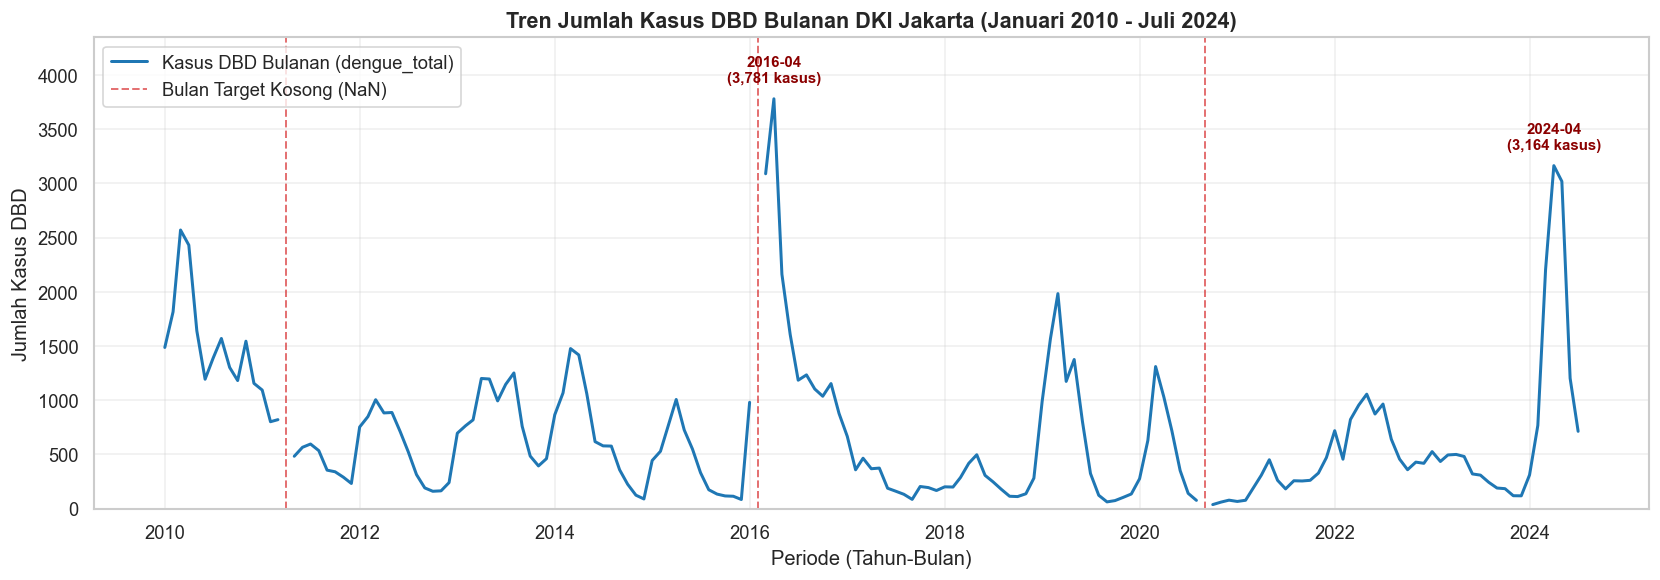

In [5]:
df_plot = df_merged.copy()
df_plot["date_dt"] = pd.to_datetime(df_plot["date"])

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_plot["date_dt"], df_plot["dengue_total"], color="#1f77b4", linewidth=1.8, label="Kasus DBD Bulanan (dengue_total)")

# Tandai 3 bulan NaN dengan garis vertikal putus-putus
nan_dates = df_plot[df_plot["dengue_total"].isna()]["date_dt"]
for i, d in enumerate(nan_dates):
    ax.axvline(d, color="#d62728", linestyle="--", alpha=0.65, linewidth=1.2,
               label="Bulan Target Kosong (NaN)" if i == 0 else None)

# Anotasi puncak tertinggi
top_peaks = df_plot.nlargest(2, "dengue_total")
for _, row in top_peaks.iterrows():
    ax.annotate(
        f"{row['ym']}\n({int(row['dengue_total']):,} kasus)",
        xy=(row["date_dt"], row["dengue_total"]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="#8b0000",
    )

ax.set_title("Tren Jumlah Kasus DBD Bulanan DKI Jakarta (Januari 2010 - Juli 2024)", fontsize=13, fontweight="bold")
ax.set_xlabel("Periode (Tahun-Bulan)")
ax.set_ylabel("Jumlah Kasus DBD")
ax.set_ylim(0, df_plot["dengue_total"].max() * 1.15)
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_01_dengue_timeseries.png", dpi=150)
plt.show()

**Insight Visualisasi 1:** Kasus DBD di DKI Jakarta memperlihatkan pola siklikal tahunan yang berulang sekaligus gelombang wabah besar periodik, dengan dua puncak ekstrem tertinggi terjadi pada **April 2016 (`3.781` kasus)** dan **April-Mei 2024 (`3.164` kasus)**. Tiga garis merah putus-putus (`2011-04`, `2016-02`, `2020-09`) menunjukkan celah tunggal 1 bulan yang tepat berada di antara data bulan tetangganya.

### Visualisasi 2: Pola Musiman Bulanan DBD terhadap Curah Hujan dan Kelembapan

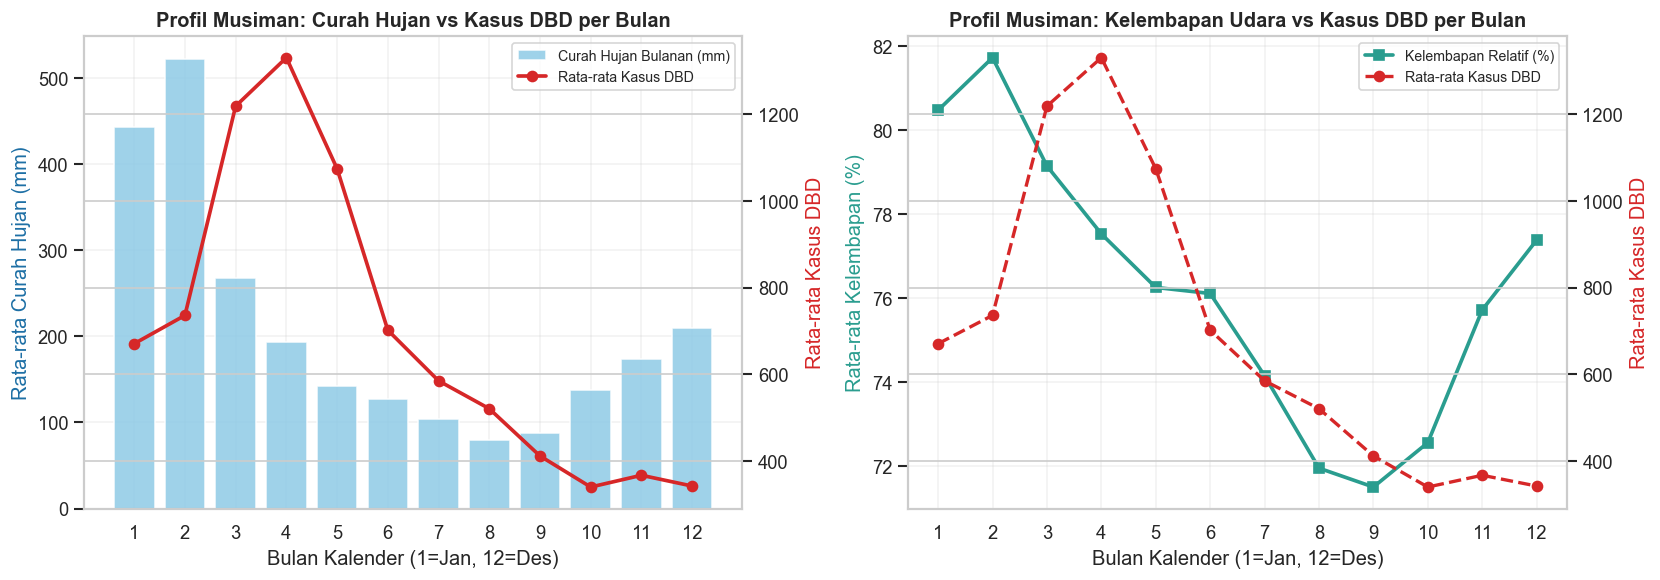

Ringkasan rata-rata musiman (Bulan 1-6):


,month,dengue_total,RR_total,RH_avg
0,1,670.73,442.29,80.48
1,2,736.07,522.10,81.73
2,3,1218.67,267.75,79.15
3,4,1330.43,193.43,77.53
4,5,1074.27,142.19,76.25
5,6,701.93,126.56,76.11


In [6]:
seasonal = df_plot.groupby("month")[["dengue_total", "RR_total", "RH_avg"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot A: Rata-rata Kasus DBD vs Curah Hujan per Bulan Kalender
ax1 = axes[0]
bars = ax1.bar(seasonal["month"], seasonal["RR_total"], color="#8ecae6", alpha=0.85, label="Curah Hujan Bulanan (mm)")
ax1_twin = ax1.twinx()
line1 = ax1_twin.plot(seasonal["month"], seasonal["dengue_total"], color="#d62728", marker="o", linewidth=2.2, label="Rata-rata Kasus DBD")
ax1.set_title("Profil Musiman: Curah Hujan vs Kasus DBD per Bulan", fontweight="bold")
ax1.set_xlabel("Bulan Kalender (1=Jan, 12=Des)")
ax1.set_ylabel("Rata-rata Curah Hujan (mm)", color="#1d6fa5")
ax1_twin.set_ylabel("Rata-rata Kasus DBD", color="#d62728")
ax1.set_xticks(range(1, 13))
ax1.grid(alpha=0.25)

# Gabung legend kedua axis
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1_twin.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8.5)

# Subplot B: Kelembapan Relatif vs Kasus DBD per Bulan
ax2 = axes[1]
ax2.plot(seasonal["month"], seasonal["RH_avg"], color="#2a9d8f", marker="s", linewidth=2.2, label="Kelembapan Relatif (%)")
ax2_twin = ax2.twinx()
ax2_twin.plot(seasonal["month"], seasonal["dengue_total"], color="#d62728", marker="o", linestyle="--", linewidth=2.0, label="Rata-rata Kasus DBD")
ax2.set_title("Profil Musiman: Kelembapan Udara vs Kasus DBD per Bulan", fontweight="bold")
ax2.set_xlabel("Bulan Kalender (1=Jan, 12=Des)")
ax2.set_ylabel("Rata-rata Kelembapan (%)", color="#2a9d8f")
ax2_twin.set_ylabel("Rata-rata Kasus DBD", color="#d62728")
ax2.set_xticks(range(1, 13))
ax2.grid(alpha=0.25)

h3, l3 = ax2.get_legend_handles_labels()
h4, l4 = ax2_twin.get_legend_handles_labels()
ax2.legend(h3 + h4, l3 + l4, loc="upper right", fontsize=8.5)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_02_seasonality_profile.png", dpi=150)
plt.show()

print("Ringkasan rata-rata musiman (Bulan 1-6):")
display(seasonal.head(6).round(2))

**Insight Visualisasi 2:** Puncak curah hujan dan kelembapan di DKI Jakarta terjadi sekitar bulan **Januari-Februari**, sedangkan puncak rata-rata kasus DBD muncul **1 hingga 2 bulan setelahnya**, yakni pada **Maret-Mei**. Fenomena pergeseran fase ini menjadi bukti visual kuat bagi penggunaan fitur *time lag* 1-2 bulan.

### Visualisasi 3: Distribusi & Deteksi Outlier Variabel Utama

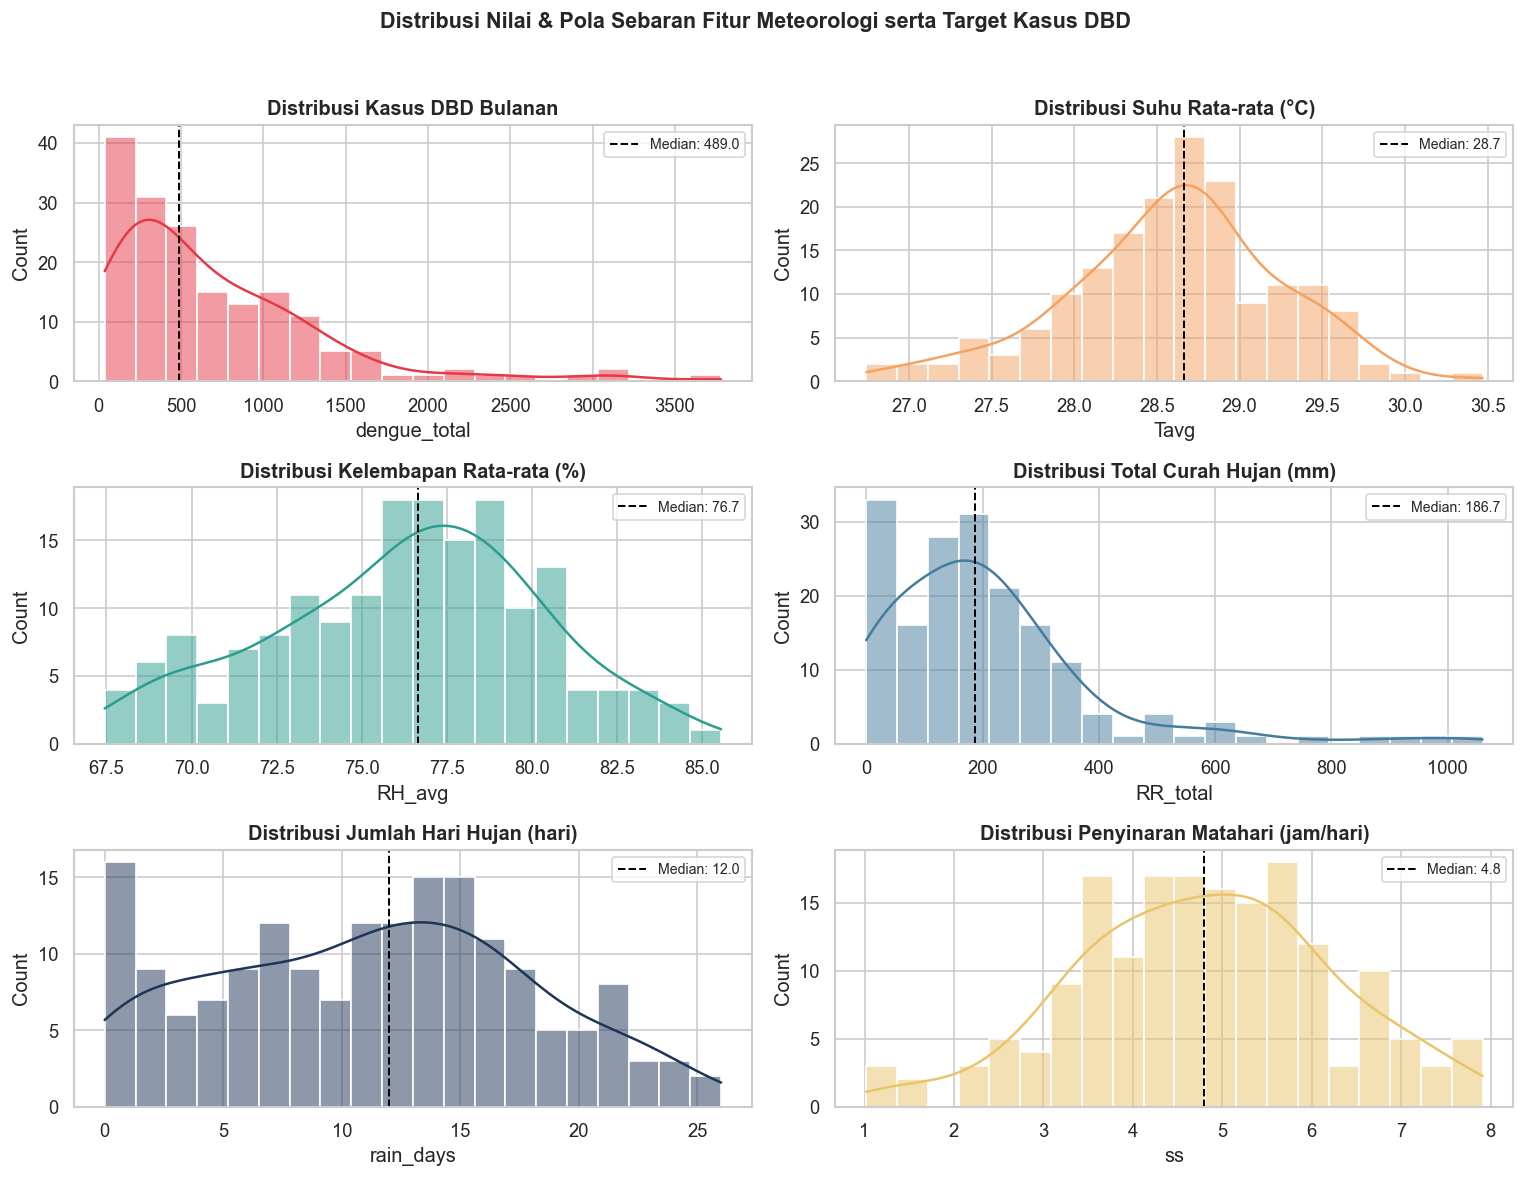

In [7]:
eda_cols = [
    ("dengue_total", "Kasus DBD Bulanan", "#e63946"),
    ("Tavg", "Suhu Rata-rata (°C)", "#f4a261"),
    ("RH_avg", "Kelembapan Rata-rata (%)", "#2a9d8f"),
    ("RR_total", "Total Curah Hujan (mm)", "#457b9d"),
    ("rain_days", "Jumlah Hari Hujan (hari)", "#1d3557"),
    ("ss", "Penyinaran Matahari (jam/hari)", "#e9c46a"),
]

fig, axes = plt.subplots(3, 2, figsize=(13, 10))
for ax, (col, title, color) in zip(axes.flatten(), eda_cols):
    sns.histplot(df_merged[col].dropna(), kde=True, color=color, ax=ax, bins=20)
    ax.axvline(df_merged[col].median(), color="black", linestyle="--", linewidth=1.2, label=f"Median: {df_merged[col].median():.1f}")
    ax.set_title(f"Distribusi {title}", fontweight="bold")
    ax.set_xlabel(col)
    ax.legend(fontsize=8.5)

fig.suptitle("Distribusi Nilai & Pola Sebaran Fitur Meteorologi serta Target Kasus DBD", fontsize=13, fontweight="bold", y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(FIGURES_DIR / "fig_03_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight Visualisasi 3:** Variabel `dengue_total` dan `RR_total` menunjukkan kemiringan ke kanan (*positively skewed*) dengan ekor panjang akibat kejadian KLB dan bulan puncak musim hujan. Sebaliknya, `Tavg` dan `RH_avg` berdistribusi relatif simetris dengan rentang sempit khas iklim tropis DKI Jakarta (suhu mayoritas 27-29 °C, kelembapan 70-85%). Perbedaan skala antar variabel ini melatarbelakangi perlunya standardisasi sebelum pemodelan.

### Visualisasi 4: Analisis Korelasi Time Lag (Lag 0 s.d. Lag 3 Bulan)

,Lag 0 bln,Lag 1 bln,Lag 2 bln,Lag 3 bln
Tn,0.088,-0.123,-0.197,-0.105
Tx,0.024,-0.207,-0.308,-0.202
Tavg,0.072,-0.154,-0.242,-0.127
RH_avg,0.289,0.480,0.525,0.388
RR_total,0.096,0.334,0.434,0.348
RR_mean,0.091,0.331,0.427,0.338
rain_days,0.242,0.460,0.534,0.417
ss,-0.167,-0.332,-0.416,-0.349
ff_x,-0.155,-0.081,-0.058,0.023
ff_avg,0.080,0.087,0.098,0.103


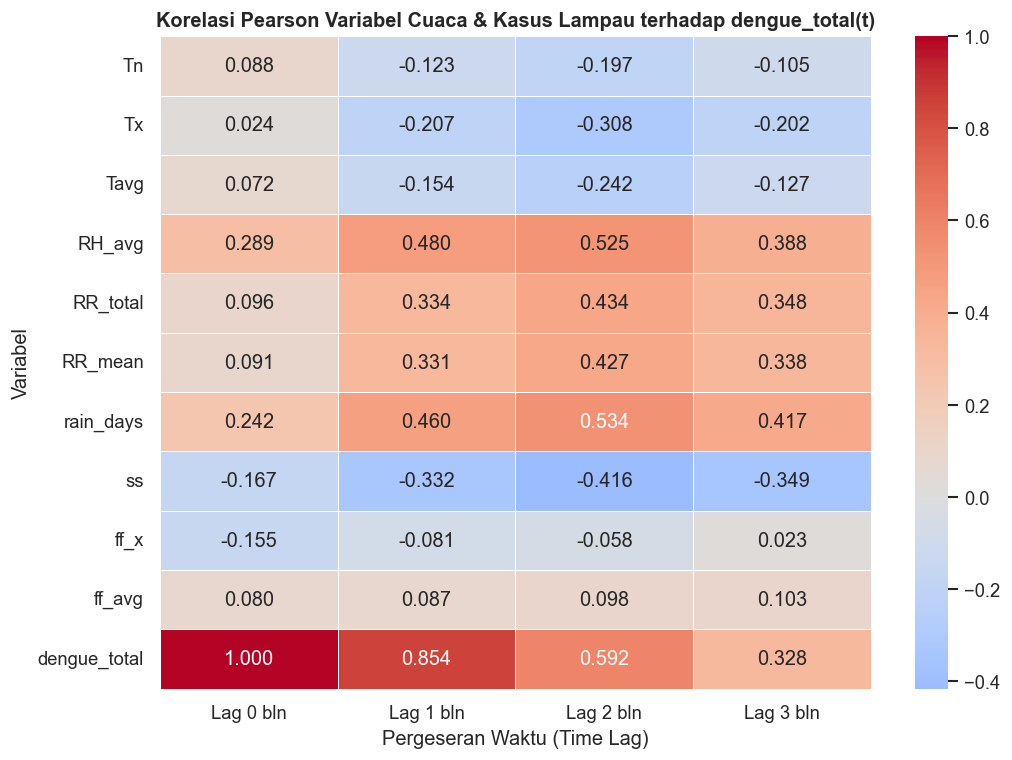

In [8]:
weather_vars = ["Tn", "Tx", "Tavg", "RH_avg", "RR_total", "RR_mean", "rain_days", "ss", "ff_x", "ff_avg", "dengue_total"]
lag_corr_dict = {}
for lag in [0, 1, 2, 3]:
    shifted = df_merged[weather_vars].shift(lag)
    lag_corr_dict[f"Lag {lag} bln"] = shifted.corrwith(df_merged["dengue_total"])

df_lag_corr = pd.DataFrame(lag_corr_dict).round(3)
display(df_lag_corr)

fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(
    df_lag_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Korelasi Pearson Variabel Cuaca & Kasus Lampau terhadap dengue_total(t)", fontsize=12, fontweight="bold")
ax.set_xlabel("Pergeseran Waktu (Time Lag)")
ax.set_ylabel("Variabel")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_04_lag_correlation_heatmap.png", dpi=150)
plt.show()

**Insight Visualisasi 4:**
- Pengaruh cuaca bulan yang sama (**Lag 0**) terhadap kasus DBD tergolong lemah (`RR_total = 0.096`, `Tavg = 0.072`).
- Korelasi meningkat tajam dan **mencapai puncaknya pada Lag 2 bulan**: `rain_days` (`0.534`), `RH_avg` (`0.525`), `RR_total` (`0.434`), serta korelasi negatif durasi penyinaran `ss` (`-0.416`) dan suhu maksimum `Tx` (`-0.308`), lalu mulai menurun kembali pada Lag 3 bulan.
- Pada `dengue_total`, autokorelasi **Lag 1 bulan** sangat tinggi (`0.854`), yang mengonfirmasi mengapa model **Naive Baseline** ($\hat{y}_t = y_{t-1}$) merupakan batas bawah ilmiah yang sangat relevan.

## Ringkasan Data Understanding (Bab 4)

### Data Analysis Key Findings
- Dataset integrasi final (`dki_jakarta_dengue_weather_2010_2024_monthly.csv`) berukuran **175 baris bulanan x 15 kolom** mencakup periode **Januari 2010 s.d. Juli 2024** di Provinsi DKI Jakarta.
- Seluruh 10 fitur cuaca dari Stasiun BMKG Kemayoran (`96745`) & Tanjung Priok (`96741`) sudah bersih (`0` missing value setelah pembersihan kode `8888`/`9999`), sedangkan kolom target `dengue_total` memiliki **3 bulan kosong terisolasi (1,71%)**: `2011-04`, `2016-02`, dan `2020-09`.
- Tidak ditemukan baris duplikat maupun celah bulan kalender yang hilang (`0` duplikat, 175 bulan berurutan).
- Profil musiman dan heatmap *time lag* membuktikan bahwa lonjakan curah hujan & kelembapan mendahului lonjakan kasus DBD dengan puncak korelasi pada **Lag 2 bulan** (`rain_days r = 0.534`, `RH_avg r = 0.525`, `RR_total r = 0.434`), sementara autokorelasi kasus `t-1` mencapai `0.854`.

### Insights or Next Steps
- Melanjutkan ke `02_data_preparation.ipynb` (Bab 5.1 - 5.4) untuk melakukan interpolasi linear deret waktu pada 3 celah bulan target secara terisolasi per partisi tanpa menyentuh outlier KLB.
- Membentuk fitur prediktor berbasis **lag 1 dan lag 2 bulan** (`t-1`, `t-2`), *rolling mean* 2 bulan (`shift 1`), serta encoding siklikal bulan (`month_sin`, `month_cos`) **tanpa menyertakan fitur cuaca `lag 0`**, diikuti pembagian data kronologis `70:15:15` dan standardisasi yang di-*fit* hanya pada data latih.